## 1. Setup — الإعداد

**English:** Compare SVM, Neural Network, KNN, and Random Forest on YESNO words. Run the cells in order. A GPU is not required.

**العربي:** مقارنة أربعة مصنّفات لكلمات نعم ولا. شغّل الخلايا بالتسلسل؛ لا يحتاج GPU.

In [22]:
%pip -q install librosa soundfile scikit-learn pandas matplotlib

import json
import time
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import matplotlib.pyplot as plt
import torch
import torchaudio

from IPython.display import Audio, display
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, ConfusionMatrixDisplay
)

SEED = 42
ROOT = Path("/content/yesno_complete_data")
OUT = Path("/content/YESNO_bilingual_results")
ROOT.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)

print("Student: Ali Nasif Jasim")
print("Student ID: 404131076")
print("Course: Digital Speech Processing")
print("PyTorch:", torch.__version__)
print("Torchaudio:", torchaudio.__version__)

Student: Ali Nasif Jasim
Student ID: 404131076
Course: Digital Speech Processing
PyTorch: 2.11.0+cpu
Torchaudio: 2.11.0+cpu


## 2. Dataset — البيانات

**English:** Load 60 Hebrew recordings from torchaudio YESNO. The labels are 0 = NO (Lo), 1 = YES (Ken).

**العربي:** تحميل 60 تسجيلًا باللغة العبرية. الرمز 0 يعني لا، والرمز 1 يعني نعم.

In [23]:
dataset = torchaudio.datasets.YESNO(
    root=str(ROOT),
    url="https://www.openslr.org/resources/1/waves_yesno.tar.gz",
    download=True
)

audio_files = sorted((ROOT / "waves_yesno").glob("*.wav"))
assert len(audio_files) == 60

def load_audio(path):
    audio, sr = sf.read(path, dtype="float32")
    if audio.ndim == 2:
        audio = audio.mean(axis=1)
    return audio, sr

print("Recordings:", len(audio_files))

Recordings: 60


## 3. Audio Exploration — فحص الصوت

**English:** Listen to a sample and inspect its waveform, spectrogram, sample rate, and label sequence.

**العربي:** سماع عينة وفحص الموجة والمخطط الطيفي ومعدل أخذ العينات وتسلسل التسميات.

File: 0_0_0_0_1_1_1_1.wav
Sample rate: 8000 Hz
Duration: 6.35 seconds
Labels: [0, 0, 0, 0, 1, 1, 1, 1]


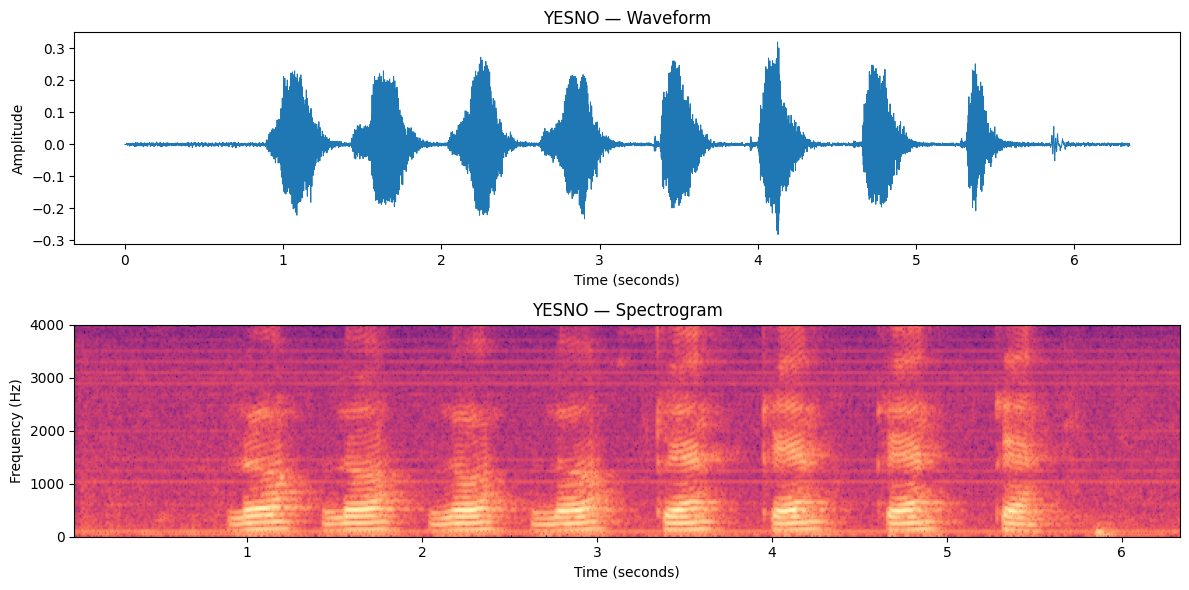

In [24]:
sample_path = audio_files[0]
signal, sample_rate = load_audio(sample_path)
labels = [int(v) for v in sample_path.stem.split("_")]

print("File:", sample_path.name)
print("Sample rate:", sample_rate, "Hz")
print("Duration:", round(len(signal) / sample_rate, 2), "seconds")
print("Labels:", labels)
display(Audio(signal, rate=sample_rate))

fig, axes = plt.subplots(2, 1, figsize=(12, 6))

axes[0].plot(np.arange(len(signal)) / sample_rate, signal, linewidth=0.7)
axes[0].set(title="YESNO — Waveform",
            xlabel="Time (seconds)", ylabel="Amplitude")

axes[1].specgram(
    signal, NFFT=256, Fs=sample_rate,
    noverlap=192, cmap="magma"
)
axes[1].set(title="YESNO — Spectrogram",
            xlabel="Time (seconds)", ylabel="Frequency (Hz)")

fig.tight_layout()
fig.savefig(OUT / "audio_exploration.png", dpi=180)
plt.show()

## 4. Segmentation Functions — دوال تقسيم الكلمات

**English:** Use silence-based segmentation. Three recordings use a finer threshold search and wider boundaries, checked by listening in the experiment. Exclude one recording with a suspected audio-label mismatch.

**العربي:** فصل الكلمات اعتمادًا على السكوت، مع بحث أدق وحدود أوسع لثلاثة تسجيلات تم تأكيدها بالسماع، واستبعاد تسجيل يُشتبه بعدم تطابق صوته مع التسميات.

In [25]:
EXCLUDED = {"0_1_0_1_0_0_0_0.wav"}
RECOVER = {
    "0_0_1_0_1_0_0_0.wav",
    "1_1_0_0_1_0_1_0.wav",
    "1_1_0_1_1_1_1_0.wav"
}

def merge_intervals(intervals, sr, gap, filter_first):
    intervals = [(int(s), int(e)) for s, e in intervals]

    if filter_first:
        intervals = [
            (s, e) for s, e in intervals
            if (e - s) / sr >= 0.12
        ]

    merged = []
    for start, end in intervals:
        if merged and (start - merged[-1][1]) / sr < gap:
            merged[-1] = (merged[-1][0], end)
        else:
            merged.append((start, end))

    if not filter_first:
        merged = [
            (s, e) for s, e in merged
            if (e - s) / sr >= 0.12
        ]

    return merged

def get_boundaries(audio, sr, expected, recovery=False):
    thresholds = range(12, 41) if recovery else [20, 25, 30, 35, 40]
    gaps = [0.02, 0.04, 0.06, 0.08] if recovery else [0.10]
    hop = 32 if recovery else 64

    for threshold in thresholds:
        raw = librosa.effects.split(
            audio, top_db=threshold,
            frame_length=256, hop_length=hop
        )
        for gap in gaps:
            intervals = merge_intervals(raw, sr, gap, not recovery)
            if len(intervals) == expected:
                return intervals, threshold

    return None, None

def expand_boundaries(intervals, audio_length, sr, padding_seconds):
    expanded = []
    padding = int(padding_seconds * sr)

    for i, (start, end) in enumerate(intervals):
        left = 0 if i == 0 else (intervals[i-1][1] + start) // 2
        right = (
            audio_length if i == len(intervals)-1
            else (end + intervals[i+1][0]) // 2
        )
        expanded.append((
            max(left, start-padding),
            min(right, end+padding)
        ))

    return expanded

print("Segmentation functions ready.")

Segmentation functions ready.


## 5. MFCC Features — استخراج الخصائص

**English:** Represent each word by 26 features: the means and standard deviations of 13 MFCC coefficients. Print the actual number of accepted recordings.

**العربي:** تمثيل كل كلمة بـ26 خاصية: المتوسط والانحراف المعياري لـ13 معامل MFCC، وعرض العدد الفعلي للتسجيلات المقبولة.

In [26]:
X, y, groups = [], [], []
metadata, excluded_records = [], []
recovered_audio = {}

for path in audio_files:
    if path.name in EXCLUDED:
        excluded_records.append({
            "file": path.name,
            "reason": "Suspected mismatch: seven audible words reported, eight labels."
        })
        continue

    audio, sr = load_audio(path)
    labels = [int(v) for v in path.stem.split("_")]
    recovery = path.name in RECOVER

    intervals, threshold = get_boundaries(
        audio, sr, len(labels), recovery
    )

    if intervals is None:
        excluded_records.append({
            "file": path.name,
            "reason": "Segmentation did not identify eight intervals."
        })
        continue

    intervals = expand_boundaries(
        intervals, len(audio), sr,
        0.12 if recovery else 0.04
    )

    if recovery:
        recovered_audio[path.name] = (audio, sr, intervals)

    for i, ((start, end), label) in enumerate(zip(intervals, labels)):
        word = audio[start:end]

        mfcc = librosa.feature.mfcc(
            y=word, sr=sr,
            n_mfcc=13, n_fft=256,
            hop_length=80, n_mels=40
        )

        X.append(np.concatenate([
            mfcc.mean(axis=1), mfcc.std(axis=1)
        ]))
        y.append(label)
        groups.append(path.name)

        metadata.append({
            "file": path.name,
            "word_index": i+1,
            "label": label,
            "start_seconds": start/sr,
            "end_seconds": end/sr,
            "top_db": threshold,
            "recovered": recovery
        })

X = np.asarray(X)
y = np.asarray(y)
groups = np.asarray(groups)

assert len(X) > 0 and np.isfinite(X).all()

print("Total recordings:", len(audio_files))
print("Used recordings:", len(np.unique(groups)))
print("Excluded recordings:", len(excluded_records))
print("Feature matrix:", X.shape)
print("NO words:", int((y == 0).sum()))
print("YES words:", int((y == 1).sum()))
display(pd.DataFrame(excluded_records))

Total recordings: 60
Used recordings: 59
Excluded recordings: 1
Feature matrix: (472, 26)
NO words: 223
YES words: 249


,file,reason
0,0_1_0_1_0_0_0_0.wav,Suspected mismatch: seven audible words report...


## 6. Boundary Review — مراجعة الحدود

**English:** Visualize the expanded boundaries of the three recovered recordings. Set PLAY_WORDS to True to listen to each word.

**العربي:** عرض الحدود الموسعة للتسجيلات الثلاثة. لسماع الكلمات غيّر PLAY_WORDS إلى True.

0_0_1_0_1_0_0_0.wav Word 1: NO


0_0_1_0_1_0_0_0.wav Word 2: NO


0_0_1_0_1_0_0_0.wav Word 3: YES


0_0_1_0_1_0_0_0.wav Word 4: NO


0_0_1_0_1_0_0_0.wav Word 5: YES


0_0_1_0_1_0_0_0.wav Word 6: NO


0_0_1_0_1_0_0_0.wav Word 7: NO


0_0_1_0_1_0_0_0.wav Word 8: NO


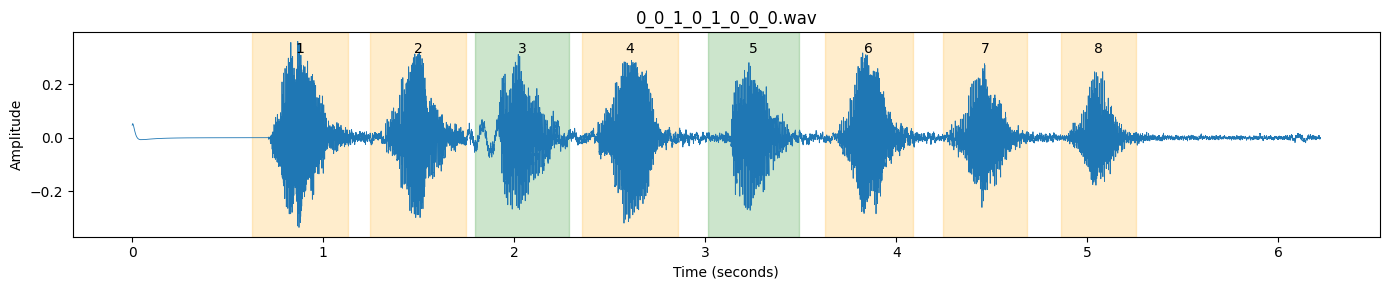

1_1_0_0_1_0_1_0.wav Word 1: YES


1_1_0_0_1_0_1_0.wav Word 2: YES


1_1_0_0_1_0_1_0.wav Word 3: NO


1_1_0_0_1_0_1_0.wav Word 4: NO


1_1_0_0_1_0_1_0.wav Word 5: YES


1_1_0_0_1_0_1_0.wav Word 6: NO


1_1_0_0_1_0_1_0.wav Word 7: YES


1_1_0_0_1_0_1_0.wav Word 8: NO


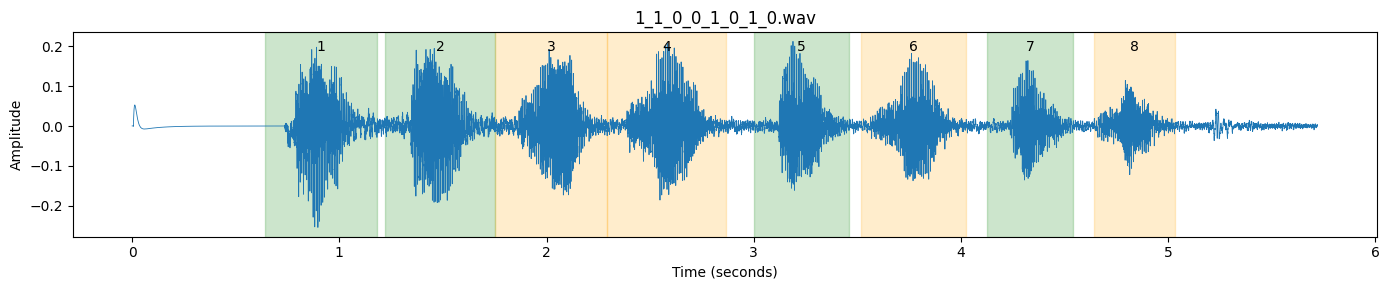

1_1_0_1_1_1_1_0.wav Word 1: YES


1_1_0_1_1_1_1_0.wav Word 2: YES


1_1_0_1_1_1_1_0.wav Word 3: NO


1_1_0_1_1_1_1_0.wav Word 4: YES


1_1_0_1_1_1_1_0.wav Word 5: YES


1_1_0_1_1_1_1_0.wav Word 6: YES


1_1_0_1_1_1_1_0.wav Word 7: YES


1_1_0_1_1_1_1_0.wav Word 8: NO


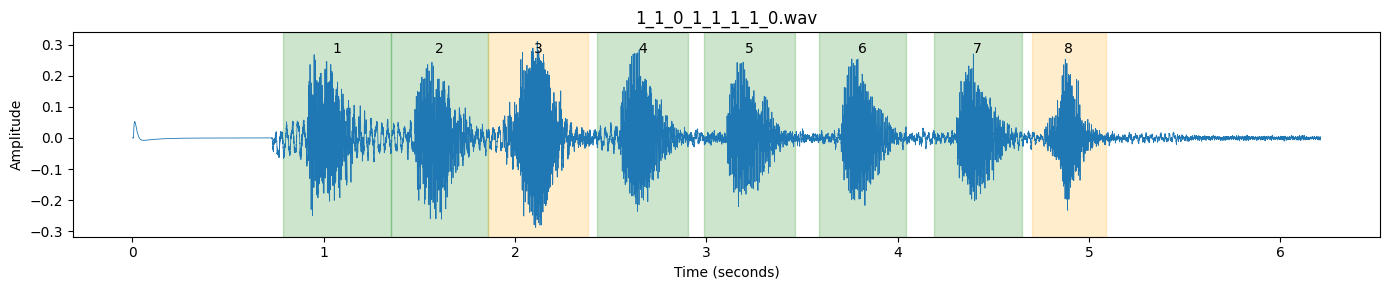

In [27]:
PLAY_WORDS = True
for filename, (audio, sr, intervals) in recovered_audio.items():
    labels = [int(v) for v in Path(filename).stem.split("_")]

    fig, ax = plt.subplots(figsize=(14, 3))
    ax.plot(np.arange(len(audio))/sr, audio, linewidth=0.6)

    for i, ((start, end), label) in enumerate(zip(intervals, labels)):
        ax.axvspan(
            start/sr, end/sr, alpha=0.2,
            color="green" if label else "orange"
        )
        ax.text(
            (start+end)/(2*sr), ax.get_ylim()[1]*0.8,
            str(i+1), ha="center"
        )

        if PLAY_WORDS:
            print(filename, f"Word {i+1}:", "YES" if label else "NO")
            display(Audio(audio[start:end], rate=sr))

    ax.set(title=filename, xlabel="Time (seconds)", ylabel="Amplitude")
    fig.tight_layout()
    fig.savefig(OUT / f"{Path(filename).stem}_boundaries.png", dpi=180)
    plt.show()

## 7. Train/Test Split — تقسيم التدريب والاختبار

**English:** Use an approximately 80/20 recording-level split with seed 42. All words from one recording remain in the same set.

**العربي:** تقسيم التسجيلات بنسبة تقارب 80/20 وبذرة 42، مع إبقاء كلمات التسجيل الواحد داخل مجموعة واحدة لمنع تداخل التسجيلات.

In [28]:
splitter = GroupShuffleSplit(
    n_splits=1, test_size=0.20, random_state=SEED
)
train_idx, test_idx = next(splitter.split(X, y, groups))

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

train_files = set(groups[train_idx])
test_files = set(groups[test_idx])

assert train_files.isdisjoint(test_files)
assert len(np.unique(y_train)) == len(np.unique(y_test)) == 2

print("Training recordings:", len(train_files))
print("Test recordings:", len(test_files))
print("Training words:", len(y_train))
print("Test words:", len(y_test))
print("Shared recordings:", len(train_files & test_files))

Training recordings: 47
Test recordings: 12
Training words: 376
Test words: 96
Shared recordings: 0


## 8. Train and Evaluate — التدريب والتقييم

**English:** Train four classifiers using the same split. Scaling is fitted only on training data. Precision, recall and F1 use YES as the positive class.

**العربي:** تدريب أربعة نماذج بالتقسيم نفسه، مع تقييس الخصائص من التدريب فقط. تحسب Precision وRecall وF1 باعتبار YES الفئة الموجبة.

In [29]:
models = {
    "SVM": make_pipeline(
        StandardScaler(), SVC(kernel="rbf", C=1.0)
    ),
    "Neural Network": make_pipeline(
        StandardScaler(),
        MLPClassifier(
            hidden_layer_sizes=(64, 32), solver="lbfgs",
            max_iter=2000, random_state=SEED
        )
    ),
    "KNN": make_pipeline(
        StandardScaler(), KNeighborsClassifier(n_neighbors=5)
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=SEED, n_jobs=-1
    )
}

rows, predictions, reports = [], {}, []

for name, model in models.items():
    start = time.perf_counter()
    model.fit(X_train, y_train)
    elapsed = time.perf_counter() - start

    pred = model.predict(X_test)
    predictions[name] = pred

    rows.append({
        "Model": name,
        "Train Accuracy": accuracy_score(
            y_train, model.predict(X_train)
        ),
        "Test Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "Training Seconds": elapsed
    })

    report = classification_report(
        y_test, pred, labels=[0, 1],
        target_names=["NO", "YES"],
        digits=4, zero_division=0
    )
    print("\n" + name + "\n" + report)
    reports.append(name + "\n" + report)

results = pd.DataFrame(rows).sort_values(
    "Test Accuracy", ascending=False
)
display(results.round(6))


SVM
              precision    recall  f1-score   support

          NO     1.0000    1.0000    1.0000        43
         YES     1.0000    1.0000    1.0000        53

    accuracy                         1.0000        96
   macro avg     1.0000    1.0000    1.0000        96
weighted avg     1.0000    1.0000    1.0000        96


Neural Network
              precision    recall  f1-score   support

          NO     1.0000    1.0000    1.0000        43
         YES     1.0000    1.0000    1.0000        53

    accuracy                         1.0000        96
   macro avg     1.0000    1.0000    1.0000        96
weighted avg     1.0000    1.0000    1.0000        96


KNN
              precision    recall  f1-score   support

          NO     1.0000    1.0000    1.0000        43
         YES     1.0000    1.0000    1.0000        53

    accuracy                         1.0000        96
   macro avg     1.0000    1.0000    1.0000        96
weighted avg     1.0000    1.0000    1.0000     

,Model,Train Accuracy,Test Accuracy,Precision,Recall,F1,Training Seconds
0,SVM,1.0,1.0,1.0,1.0,1.0,0.005837
1,Neural Network,1.0,1.0,1.0,1.0,1.0,0.371567
2,KNN,1.0,1.0,1.0,1.0,1.0,0.007000
3,Random Forest,1.0,1.0,1.0,1.0,1.0,0.482300


## 9. Visual Comparison — المقارنة بالرسومات

**English:** Plot test accuracy and confusion matrices. Diagonal entries indicate correctly classified words.

**العربي:** رسم دقة الاختبار ومصفوفات الالتباس؛ الأعداد على القطر تمثل الكلمات المصنفة بصورة صحيحة.

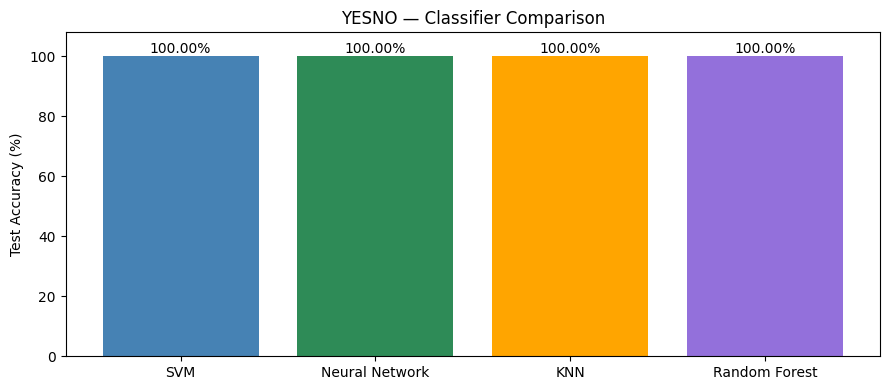

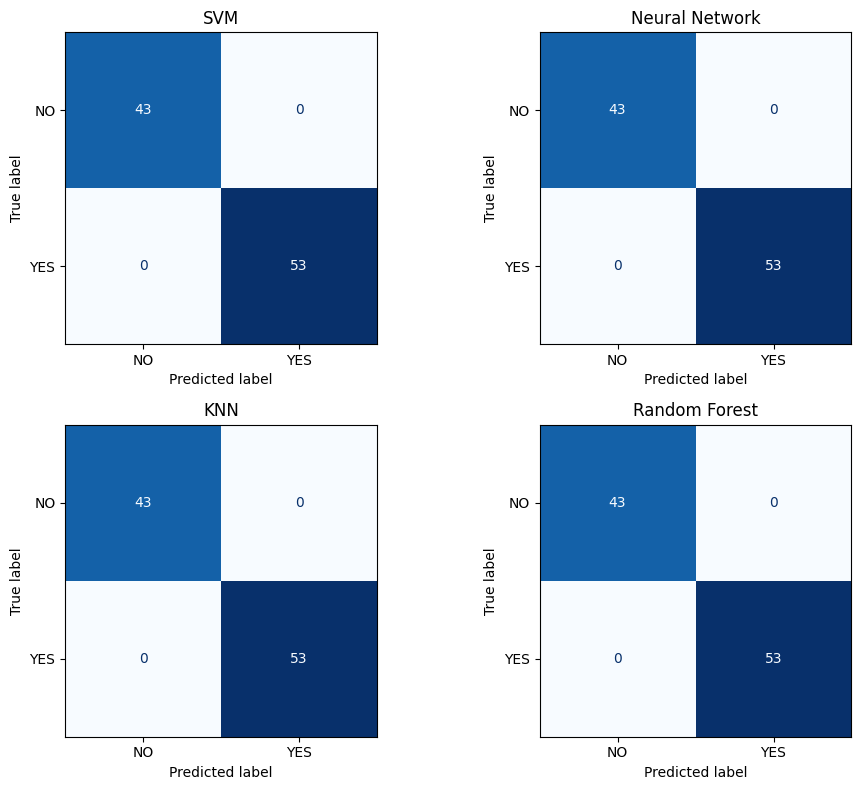

In [21]:
fig, ax = plt.subplots(figsize=(9, 4))
values = results["Test Accuracy"].to_numpy()*100

ax.bar(
    results["Model"], values,
    color=["steelblue", "seagreen", "orange", "mediumpurple"]
)
ax.set(
    ylim=(0, 108), ylabel="Test Accuracy (%)",
    title="YESNO — Classifier Comparison"
)

for i, value in enumerate(values):
    ax.text(i, value+1, f"{value:.2f}%", ha="center")

fig.tight_layout()
fig.savefig(OUT / "accuracy_comparison.png", dpi=200)
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for ax, (name, pred) in zip(axes.flat, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, labels=[0, 1],
        display_labels=["NO", "YES"],
        cmap="Blues", colorbar=False, ax=ax
    )
    ax.set_title(name)

fig.tight_layout()
fig.savefig(OUT / "confusion_matrices.png", dpi=200)
plt.show()

## 10. Conclusions and Export — الاستنتاجات وحفظ النتائج

**English:** Summarize the measured results and export them. These results describe one recording-level split from a single-speaker dataset; they do not establish performance on new speakers. Training times vary between runs.

**العربي:** تلخيص النتائج وحفظها. التقييم يخص تقسيمًا واحدًا لبيانات متحدث واحد، ولا يثبت الأداء على متحدثين جدد. أوقات التدريب تختلف بين مرات التشغيل.

In [30]:
for _, row in results.iterrows():
    print(f"{row['Model']}: {row['Test Accuracy']*100:.2f}% test accuracy")

fastest = results.loc[results["Training Seconds"].idxmin(), "Model"]
print("Shortest training time in this run:", fastest)

results.to_csv(OUT / "classifier_results.csv", index=False)

segments = pd.DataFrame(metadata)
segments["split"] = [
    "train" if name in train_files else "test"
    for name in segments["file"]
]
segments.to_csv(OUT / "word_segments.csv", index=False)

test_predictions = segments.iloc[test_idx].reset_index(drop=True).copy()
test_predictions["true_label"] = y_test
for name, pred in predictions.items():
    test_predictions[name] = pred
test_predictions.to_csv(OUT / "test_predictions.csv", index=False)

pd.DataFrame(excluded_records).to_csv(
    OUT / "excluded_recordings.csv", index=False
)

(OUT / "classification_reports.txt").write_text(
    "\n\n".join(reports), encoding="utf-8"
)

summary = {
    "seed": SEED,
    "total_recordings": len(audio_files),
    "used_recordings": len(np.unique(groups)),
    "excluded_recordings": excluded_records,
    "feature_shape": list(X.shape),
    "train_recordings": sorted(train_files),
    "test_recordings": sorted(test_files),
    "train_words": len(y_train),
    "test_words": len(y_test),
    "features": "13 MFCC means + 13 MFCC standard deviations",
    "positive_class": "YES (1)",
    "limitations": "One recording-level split; no new-speaker evaluation."
}
(OUT / "experiment_summary.json").write_text(
    json.dumps(summary, indent=2), encoding="utf-8"
)

np.savez_compressed(
    OUT / "features_and_split.npz",
    X=X, y=y, groups=groups,
    train_idx=train_idx, test_idx=test_idx
)

zip_path = shutil.make_archive(
    "/content/YESNO_bilingual_results", "zip", root_dir=OUT
)

from google.colab import files
files.download(zip_path)

SVM: 100.00% test accuracy
Neural Network: 100.00% test accuracy
KNN: 100.00% test accuracy
Random Forest: 100.00% test accuracy
Shortest training time in this run: SVM


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>